> 🔑 **SOLUTION EDITION.** This copy contains worked answers to every exercise. Try the student notebook first - you learn by struggling a little!

In [1]:
# (Solution edition only) make the course helper module importable from this folder
import sys; sys.path.insert(0, '../notebooks')

# 🌽 Project 2: Farmer Segmentation by Production Patterns
### *One training programme can't fit a 1.5-acre maize plot and a 40-acre wheat estate.*

**⏱ about 3 hours · Uses:** data cleaning, outliers, PCA, K-Means, hierarchical clustering, stability, tree-based explanation (Lessons 1, 2, 4, 6)

---

## 📨 The brief

> **From:** Dr. Amina Odhiambo, Director of Extension Services, County Agriculture Office
> **To:** You, the data analyst
> **Subject:** Who are our farmers, really?
>
> *We have 700 farmers in the county's registry. Our extension officers use the same training package for everyone and uptake is poor. I need to know **what types of farmer we actually have based on how they produce**, **what each type struggles with**, and **a rule my officers can use in the field to recognise which type they're talking to**. We have funds for roughly four programmes.*

## 🎯 What you'll deliver
1. A **cleaned** dataset (missing values and outliers handled, with reasons).
2. A **PCA exploration** showing the main axes of variation among farmers.
3. **Farmer segments** with names, sizes, and diagnostic profiles.
4. A **programme design** table linking each segment to its main constraint.
5. A **3-question field rule** (decision tree) extension officers can apply on the farm.
6. A **brief** for Dr. Odhiambo.

## 🗺️ Milestones

| # | Milestone | Skills |
|---|---|---|
| 1 | Audit: missingness and outliers | IQR rule, pandas |
| 2 | Prepare features | imputation, log, scaling, feature choice |
| 3 | Explore with PCA | variance, loadings |
| 4 | Cluster and validate | k selection, stability, cross-check |
| 5 | Profile and name | relative heatmap |
| 6 | Programme design & geography | groupby, crosstab |
| 7 | A rule for the field | decision tree |
| 8 | Reveal (optional) | external validation |
| 9 | The brief | communication |

## 📏 Grading rubric (100 points)

| Criterion | Points |
|---|---|
| Cleaning decisions are correct and justified (esp. **excluding revenue** from the features, and handling outliers) | 15 |
| PCA interpreted (components *named*) | 10 |
| *k* justified with ≥ 3 kinds of evidence, cross-checked with Ward | 20 |
| Segments named from profiles | 15 |
| Programme design is specific, linked to the data | 15 |
| Field rule is accurate (> 80%) and *simple* | 10 |
| Brief: clear, honest, actionable | 15 |

In [2]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.metrics import silhouette_score, adjusted_rand_score, calinski_harabasz_score
from course_utils import set_style, load, check, profile_clusters, PALETTE
set_style()
RANDOM_STATE = 42

farmers = load("farmers")
farmers.head()

,farmer_id,county,primary_crop,farm_size_acres,yield_bags_per_acre,fertilizer_kg_per_acre,irrigated,labour_days_per_acre,improved_seed,coop_member,distance_to_market_km,post_harvest_loss_pct,experience_years,extension_visits_per_year,annual_revenue_kes
0,F0280,Trans Nzoia,Maize,29.79,36.2,72.4,0,4.2,1,0,4.1,8.4,1,0,2939400
1,F0591,Nakuru,Potatoes,7.83,22.0,27.6,0,23.0,0,1,5.1,9.2,1,2,501200
2,F0446,Nyeri,French Beans,3.48,38.4,32.0,1,88.9,1,1,9.3,6.6,10,3,414100
3,F0084,Narok,Beans,1.26,10.1,19.4,0,34.3,0,0,10.5,26.9,10,2,32000
4,F0460,Machakos,Onions,1.78,34.7,114.2,1,47.9,1,0,8.7,25.6,1,3,141600


### 📖 Data dictionary: `farmers.csv`

| Column | Meaning |
|---|---|
| `farmer_id`, `county`, `primary_crop` | Identifiers / categories (**not** numeric features) |
| `farm_size_acres` | Land under cultivation |
| `yield_bags_per_acre` | Average yield |
| `fertilizer_kg_per_acre` | Fertiliser use *(some missing)* |
| `irrigated` | 1 if irrigated |
| `labour_days_per_acre` | Labour intensity |
| `improved_seed` | 1 if uses improved seed |
| `coop_member` | 1 if member of a co-operative |
| `distance_to_market_km` | Distance to nearest market *(some missing)* |
| `post_harvest_loss_pct` | % of harvest lost after harvesting *(some missing)* |
| `experience_years`, `extension_visits_per_year` | Experience and contact with extension |
| `annual_revenue_kes` | Revenue ≈ size × yield × price × (1 − loss) |

> 🤔 **Think before you cluster:** The brief says *"based on how they produce"*. Which columns describe **production practices**, and which are **outcomes** (revenue) or **labels** (county, crop)? Using outcomes as features double-counts size and yield.

## Milestone 1 · Audit: missingness and outliers 🔍

### 🧩 Milestone 1: Find the problems
**Difficulty:** ⭐⭐  |  **Time:** ~12 min

Compute:
- `missing_by_col`: a Series of missing counts per column, **only columns with ≥ 1 missing**
- `n_missing_cells`: total missing cells in the whole DataFrame
- `iqr_upper`: the **Tukey upper fence** for `farm_size_acres`: `Q3 + 1.5 × IQR`
- `n_size_outliers`: number of farms **above** that fence
- `max_size`: the largest farm in acres

Then think (in a comment): are those big farms *errors* or *real*? What would you do?

<details><summary>💡 Hint 1</summary>

`missing_by_col = farmers.isna().sum(); missing_by_col = missing_by_col[missing_by_col > 0]`

</details>
<details><summary>💡 Hint 2</summary>

`q1, q3 = farmers['farm_size_acres'].quantile([0.25, 0.75]); iqr = q3 - q1`

</details>
<details><summary>💡 Hint 3</summary>

Our data has real commercial estates (30–60 acres) **and** a few suspicious values of 200+ acres. A log transform and robust handling treat both; you could also inspect the suspicious rows.

</details>

In [3]:
missing_by_col = farmers.isna().sum(); missing_by_col = missing_by_col[missing_by_col > 0]
n_missing_cells = int(farmers.isna().sum().sum())
q1, q3 = farmers["farm_size_acres"].quantile([0.25, 0.75]); iqr_upper = q3 + 1.5 * (q3 - q1)
n_size_outliers = int((farmers["farm_size_acres"] > iqr_upper).sum())
max_size = farmers["farm_size_acres"].max()
print(missing_by_col.to_dict(), n_missing_cells, round(iqr_upper, 1), n_size_outliers, max_size)
# The commercial estates (30-60 acres) are REAL and important, so we must not delete them. A few values above ~150 acres look like
# data-entry errors; log1p shrinks their pull without discarding rows.

{'fertilizer_kg_per_acre': 15, 'distance_to_market_km': 6, 'post_harvest_loss_pct': 10} 31 15.7 113 757.6


In [4]:
# ✔ Self-check (run me after you've written your answer)
check('three columns have missing values', lambda: len(missing_by_col) == 3)
check('31 missing cells in total', lambda: n_missing_cells == 31)
check('fence is positive and above the median', lambda: iqr_upper > farmers['farm_size_acres'].median())
check('there are some outliers (> 10) but not most farms', lambda: 10 < n_size_outliers < 200)
check('max farm is huge (> 150 acres)', lambda: max_size > 150)

✅ three columns have missing values
✅ 31 missing cells in total
✅ fence is positive and above the median
✅ there are some outliers (> 10) but not most farms
✅ max farm is huge (> 150 acres)


## Milestone 2 · Prepare the features 🧼

### 🧩 Milestone 2: Production-pattern features
**Difficulty:** ⭐⭐  |  **Time:** ~12 min

Create `feature_list` (a list of **8–10** column names describing **production practices**), then:

- `X_df`: those columns, **median-imputed**, with `np.log1p` applied to `farm_size_acres`
- `X_f`: `X_df` standardised (NumPy array)

**Rules:** exclude IDs, `county`, `primary_crop`, and **`annual_revenue_kes`** (an outcome that merely multiplies size × yield).

<details><summary>💡 Hint 1</summary>

Good candidates: `farm_size_acres`, `yield_bags_per_acre`, `fertilizer_kg_per_acre`, `irrigated`, `labour_days_per_acre`, `improved_seed`, `coop_member`, `distance_to_market_km`, `post_harvest_loss_pct`.

</details>
<details><summary>💡 Hint 2</summary>

`X_df = farmers[feature_list].copy(); X_df = X_df.fillna(X_df.median()); X_df['farm_size_acres'] = np.log1p(X_df['farm_size_acres'])`

</details>
<details><summary>💡 Hint 3</summary>

Whether to include `experience_years` and `extension_visits_per_year` is a judgement call: they describe the farmer, not the production system. Try with and without!

</details>

In [5]:
feature_list = ["farm_size_acres", "yield_bags_per_acre", "fertilizer_kg_per_acre", "irrigated", "labour_days_per_acre",
                "improved_seed", "coop_member", "distance_to_market_km", "post_harvest_loss_pct"]
X_df = farmers[feature_list].copy(); X_df = X_df.fillna(X_df.median()); X_df["farm_size_acres"] = np.log1p(X_df["farm_size_acres"])
X_f = StandardScaler().fit_transform(X_df)
print(X_f.shape)

(700, 9)


In [6]:
# ✔ Self-check (run me after you've written your answer)
check('8 to 10 features', lambda: 8 <= len(feature_list) <= 10)
check('revenue was excluded', lambda: 'annual_revenue_kes' not in feature_list)
check('no ids or categories', lambda: not ({'farmer_id', 'county', 'primary_crop'} & set(feature_list)))
check('700 rows, no NaN, standardised', lambda: X_f.shape[0] == 700 and not np.isnan(X_f).any() and np.allclose(X_f.std(axis=0), 1))

✅ 8 to 10 features
✅ revenue was excluded
✅ no ids or categories
✅ 700 rows, no NaN, standardised


## Milestone 3 · Explore with PCA 🔭

### 🧩 Milestone 3: The main axes of variation
**Difficulty:** ⭐⭐  |  **Time:** ~15 min

Fit a full `PCA()` on `X_f`:

- `pc1_var`: the share of variance explained by PC1
- `n_comp_90`: number of components needed for ≥ 90% of variance
- `loadings`: DataFrame of the first **3** components (rows = your features, columns `PC1..PC3`)
- `pc1_top`: the feature with the **largest absolute loading** on PC1

Draw a loadings heatmap, then **name PC1 and PC2** in a comment.

<details><summary>💡 Hint 1</summary>

`pca = PCA().fit(X_f)`; `pca.explained_variance_ratio_[0]`; `np.cumsum(...)`.

</details>
<details><summary>💡 Hint 2</summary>

`loadings = pd.DataFrame(pca.components_[:3].T, index=feature_list, columns=['PC1', 'PC2', 'PC3'])`

</details>
<details><summary>💡 Hint 3</summary>

PC1 typically contrasts *modern, productive, input-using farms* against *low-input, high-loss farms* (an 'intensification' axis).

</details>

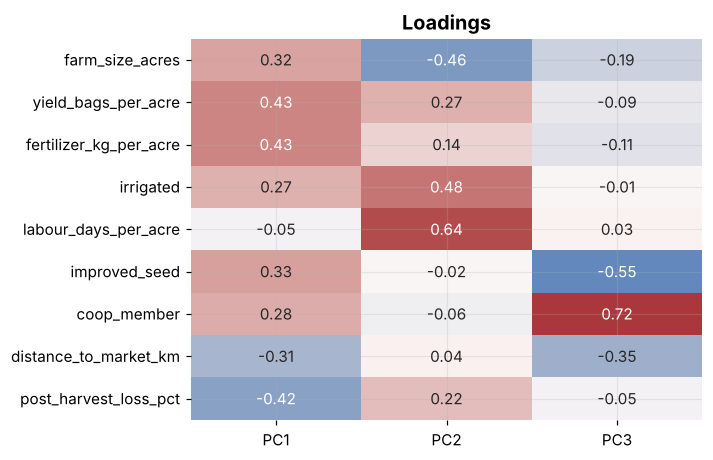

0.41 6 fertilizer_kg_per_acre


In [7]:
pca = PCA().fit(X_f)
pc1_var = pca.explained_variance_ratio_[0]
n_comp_90 = int(np.argmax(np.cumsum(pca.explained_variance_ratio_) >= 0.90)) + 1
loadings = pd.DataFrame(pca.components_[:3].T, index=feature_list, columns=["PC1", "PC2", "PC3"])
pc1_top = loadings["PC1"].abs().idxmax()
plt.figure(figsize=(6, 4.5)); sns.heatmap(loadings, annot=True, fmt=".2f", cmap="vlag", center=0, cbar=False); plt.title("Loadings"); plt.show()
print(round(pc1_var, 2), n_comp_90, pc1_top)
# PC1 = 'intensification / modernisation' (yield, fertiliser, improved seed up; losses and distance down).
# PC2 = 'labour-intensive irrigated small plots' versus large mechanised farms.

In [8]:
# ✔ Self-check (run me after you've written your answer)
check('PC1 explains between 25% and 60%', lambda: 0.25 < pc1_var < 0.6)
check('more than 2 components needed for 90%', lambda: 3 <= n_comp_90 <= len(feature_list))
check('loadings table is features x 3', lambda: loadings.shape == (len(feature_list), 3))

✅ PC1 explains between 25% and 60%
✅ more than 2 components needed for 90%
✅ loadings table is features x 3


## Milestone 4 · Cluster and validate 🔁

### 🧩 Milestone 4: Choose k and cross-check
**Difficulty:** ⭐⭐⭐  |  **Time:** ~25 min

1. For `k = 2…7` compute silhouette, Calinski–Harabasz **and** stability (reuse your Lesson 6 function; `n_pairs=6` is enough) in a DataFrame `eval_table`.
2. Choose `chosen_k` (3–6): your decision, with justification in a comment. *(Extension services can fund roughly 4 programmes.)*
3. Fit K-Means → `labels`; fit Ward with the same k → `ward_labels`; `ari_km_ward` = their ARI.

<details><summary>💡 Hint 1</summary>

Same loop as Project 1. `stability` = average ARI between models fitted on two different 80% subsamples, each labelling all farmers.

</details>
<details><summary>💡 Hint 2</summary>

Silhouette often prefers a coarser k (3 here) than a domain expert would. When the metrics are close, **actionability** can break the tie.

</details>
<details><summary>💡 Hint 3</summary>

`AgglomerativeClustering(n_clusters=chosen_k, linkage='ward').fit_predict(X_f)`

</details>

In [9]:
def stability(X, k, n_pairs=6, frac=0.8, seed=0):
    rng = np.random.default_rng(seed); n = len(X); out = []
    for _ in range(n_pairs):
        a = rng.choice(n, int(frac * n), replace=False); b = rng.choice(n, int(frac * n), replace=False)
        ma = KMeans(k, n_init=5, random_state=int(rng.integers(10**6))).fit(X[a]); mb = KMeans(k, n_init=5, random_state=int(rng.integers(10**6))).fit(X[b])
        out.append(adjusted_rand_score(ma.predict(X), mb.predict(X)))
    return float(np.mean(out))

rows = []
for k in range(2, 8):
    lab = KMeans(k, n_init=10, random_state=RANDOM_STATE).fit_predict(X_f)
    rows.append(dict(k=k, silhouette=silhouette_score(X_f, lab), calinski_harabasz=calinski_harabasz_score(X_f, lab), stability=stability(X_f, k)))
eval_table = pd.DataFrame(rows).set_index("k"); display(eval_table.round(3))

# Silhouette peaks at k=3 (0.36), but k=4 is still very stable (~0.95) and splits the middle group into horticulture vs. dairy/mixed,
# which need different programmes. The extension budget supports four programmes -> k = 4. (k=5 and beyond are clearly less stable.)
chosen_k = 4
labels = KMeans(chosen_k, n_init=10, random_state=RANDOM_STATE).fit_predict(X_f)
ward_labels = AgglomerativeClustering(n_clusters=chosen_k, linkage="ward").fit_predict(X_f)
ari_km_ward = adjusted_rand_score(labels, ward_labels); print(round(ari_km_ward, 3))

,silhouette,calinski_harabasz,stability
k,,,
2,0.309,346.669,0.994
3,0.364,395.844,0.995
4,0.310,334.839,0.948
5,0.291,291.979,0.818
6,0.273,264.270,0.798
7,0.288,243.784,0.796


0.787


In [10]:
# ✔ Self-check (run me after you've written your answer)
check('evaluated k = 2..7', lambda: list(eval_table.index) == list(range(2, 8)))
check('chosen_k between 3 and 6', lambda: 3 <= chosen_k <= 6)
check('one label per farmer', lambda: len(labels) == 700 and len(set(labels)) == chosen_k)
check('K-Means and Ward broadly agree (ARI > 0.5)', lambda: ari_km_ward > 0.5)

✅ evaluated k = 2..7
✅ chosen_k between 3 and 6
✅ one label per farmer
✅ K-Means and Ward broadly agree (ARI > 0.5)


## Milestone 5 · Profile and name 🏷️

### 🧩 Milestone 5: Farmer personas
**Difficulty:** ⭐⭐  |  **Time:** ~20 min

Build `fdf` (farmers with imputed numerics + `cluster`), then `profile = profile_clusters(fdf, labels, feature_list)` using the **original, un-logged** columns. Draw the relative heatmap and create `segment_names`: one unique, descriptive name per cluster (e.g. *"Subsistence smallholders"*).

Add `fdf["segment"]`. Finally compute `segment_sizes`: a Series of the **% of farmers** in each named segment (sums to 100).

<details><summary>💡 Hint 1</summary>

`fdf = farmers.fillna(farmers.median(numeric_only=True)).copy(); fdf['cluster'] = labels`

</details>
<details><summary>💡 Hint 2</summary>

Names come from distinctive features: tiny plots & high loss → *subsistence*; huge farms, little labour → *commercial grain*; high yield + irrigation + labour → *intensive horticulture*; high co-op membership near market → *dairy/mixed co-op*.

</details>
<details><summary>💡 Hint 3</summary>

`segment_sizes = 100 * fdf['segment'].value_counts(normalize=True)`

</details>

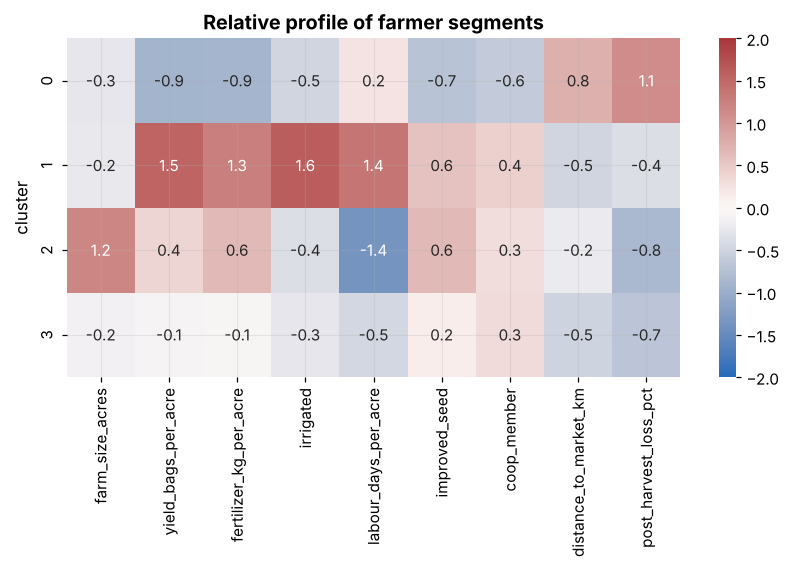

,size,share_%,farm_size_acres,yield_bags_per_acre,fertilizer_kg_per_acre,irrigated,labour_days_per_acre,improved_seed,coop_member,distance_to_market_km,post_harvest_loss_pct
cluster,,,,,,,,,,,
0,252,36.0,1.87,11.78,13.99,0.03,37.56,0.27,0.14,13.84,27.41
1,136,19.4,3.36,37.97,91.35,0.92,59.25,0.89,0.65,6.41,13.74
2,112,16.0,52.31,25.58,69.07,0.08,5.83,0.93,0.59,7.95,9.25
3,200,28.6,6.28,20.46,42.73,0.12,23.46,0.69,0.60,6.26,10.76


{0: 'Subsistence smallholders', 1: 'Intensive horticulture farmers', 2: 'Commercial grain farmers', 3: 'Dairy / mixed co-operative farmers'}
{'Subsistence smallholders': 36.0, 'Dairy / mixed co-operative farmers': 28.6, 'Intensive horticulture farmers': 19.4, 'Commercial grain farmers': 16.0}


In [11]:
fdf = farmers.fillna(farmers.median(numeric_only=True)).copy(); fdf["cluster"] = labels
profile = profile_clusters(fdf, labels, feature_list)
relative = (profile[feature_list] - fdf[feature_list].mean()) / fdf[feature_list].std()
plt.figure(figsize=(9, 4)); sns.heatmap(relative, annot=True, fmt=".1f", cmap="vlag", center=0, vmin=-2, vmax=2); plt.title("Relative profile of farmer segments"); plt.show()
display(profile)

def draft_name(r):
    if r["farm_size_acres"] > 1.0 and r["labour_days_per_acre"] < -0.5: return "Commercial grain farmers"
    if r["irrigated"] > 1.0 and r["labour_days_per_acre"] > 0.5: return "Intensive horticulture farmers"
    if r["post_harvest_loss_pct"] > 0.8 and r["fertilizer_kg_per_acre"] < -0.5: return "Subsistence smallholders"
    return "Dairy / mixed co-operative farmers"
segment_names = {c: draft_name(relative.loc[c]) for c in relative.index}
seen = {}
for c, n in segment_names.items():
    seen[n] = seen.get(n, 0) + 1
    if seen[n] > 1: segment_names[c] = f"{n} (B)"
fdf["segment"] = fdf["cluster"].map(segment_names)
segment_sizes = 100 * fdf["segment"].value_counts(normalize=True)
print(segment_names); print(segment_sizes.round(1).to_dict())

In [12]:
# ✔ Self-check (run me after you've written your answer)
check('each cluster has a unique name', lambda: set(segment_names) == set(labels) and len(set(segment_names.values())) == chosen_k)
check('sizes sum to 100', lambda: abs(segment_sizes.sum() - 100) < 1e-6)
check('fdf has a segment column', lambda: fdf['segment'].notna().all())

✅ each cluster has a unique name
✅ sizes sum to 100
✅ fdf has a segment column


## Milestone 6 · Programme design and geography 🗺️

### 🧩 Milestone 6: Who struggles with what, and where do they live?
**Difficulty:** ⭐⭐  |  **Time:** ~12 min

Using `fdf`:

1. `loss_by_segment`: mean `post_harvest_loss_pct` per segment, and `highest_loss_segment` = the segment name with the highest loss.
2. `coop_by_segment`: share (0–1) of co-op members per segment, and `lowest_coop_segment`.
3. `county_mix = pd.crosstab(fdf["county"], fdf["segment"], normalize="index")` (each county's segment mix; rows sum to 1).
4. `nakuru_top_segment`: the most common segment among Nakuru farmers.

*Then complete the programme table in the brief below.*

<details><summary>💡 Hint 1</summary>

`fdf.groupby('segment')['post_harvest_loss_pct'].mean()` then `.idxmax()`.

</details>
<details><summary>💡 Hint 2</summary>

A 0/1 column's mean is its share: `fdf.groupby('segment')['coop_member'].mean()`.

</details>
<details><summary>💡 Hint 3</summary>

`county_mix.loc['Nakuru'].idxmax()`

</details>

In [13]:
loss_by_segment = fdf.groupby("segment")["post_harvest_loss_pct"].mean(); highest_loss_segment = loss_by_segment.idxmax()
coop_by_segment = fdf.groupby("segment")["coop_member"].mean(); lowest_coop_segment = coop_by_segment.idxmin()
county_mix = pd.crosstab(fdf["county"], fdf["segment"], normalize="index")
nakuru_top_segment = county_mix.loc["Nakuru"].idxmax()
display(pd.DataFrame({"mean loss %": loss_by_segment, "co-op share": coop_by_segment}).round(2))
print(highest_loss_segment, "|", lowest_coop_segment, "|", nakuru_top_segment)

,mean loss %,co-op share
segment,,
Commercial grain farmers,9.25,0.59
Dairy / mixed co-operative farmers,10.76,0.60
Intensive horticulture farmers,13.74,0.65
Subsistence smallholders,27.41,0.14


Subsistence smallholders | Subsistence smallholders | Dairy / mixed co-operative farmers


In [14]:
# ✔ Self-check (run me after you've written your answer)
check('highest-loss segment really has the highest loss', lambda: loss_by_segment[highest_loss_segment] == loss_by_segment.max())
check('co-op shares are between 0 and 1', lambda: coop_by_segment.between(0, 1).all())
check('15 counties; each row sums to 1', lambda: county_mix.shape[0] == 15 and np.allclose(county_mix.sum(axis=1), 1))
check("Nakuru's top segment is a segment name", lambda: nakuru_top_segment in set(segment_names.values()))

✅ highest-loss segment really has the highest loss
✅ co-op shares are between 0 and 1
✅ 15 counties; each row sums to 1
✅ Nakuru's top segment is a segment name


## Milestone 7 · A rule for the field 🥾

Extension officers don't carry laptops. Can we give them **three simple questions** that identify a farmer's segment?

### 🧩 Milestone 7: A decision tree for officers
**Difficulty:** ⭐⭐  |  **Time:** ~10 min

Train `DecisionTreeClassifier(max_depth=3, random_state=0)` to predict `fdf["segment"]` from the **original** feature columns (`fdf[feature_list]`).

- `field_acc`: its accuracy
- `field_rules`: the text from `export_text(tree, feature_names=feature_list)`

Print the rules and rewrite the **top three** as plain-English questions an officer could ask (*"How many acres do you farm?"*).

<details><summary>💡 Hint 1</summary>

`tree = DecisionTreeClassifier(max_depth=3, random_state=0).fit(fdf[feature_list], fdf['segment'])`

</details>
<details><summary>💡 Hint 2</summary>

`field_acc = tree.score(fdf[feature_list], fdf['segment'])`

</details>
<details><summary>💡 Hint 3</summary>

If accuracy is below 85%, try `max_depth=4`. Is the extra complexity worth it to an officer on a hillside?

</details>

In [15]:
tree = DecisionTreeClassifier(max_depth=3, random_state=0).fit(fdf[feature_list], fdf["segment"])
field_acc = tree.score(fdf[feature_list], fdf["segment"])
field_rules = export_text(tree, feature_names=feature_list)
print(f"{field_acc:.0%} accurate\n"); print(field_rules)
# Officer's questions (example): 1) How many acres do you farm? 2) Do you irrigate / how many labour-days per acre?
# 3) Are you in a co-operative? Three questions classify most farmers correctly.

95% accurate

|--- post_harvest_loss_pct <= 19.75
|   |--- farm_size_acres <= 20.78
|   |   |--- yield_bags_per_acre <= 28.95
|   |   |   |--- class: Dairy / mixed co-operative farmers
|   |   |--- yield_bags_per_acre >  28.95
|   |   |   |--- class: Intensive horticulture farmers
|   |--- farm_size_acres >  20.78
|   |   |--- class: Commercial grain farmers
|--- post_harvest_loss_pct >  19.75
|   |--- yield_bags_per_acre <= 25.15
|   |   |--- farm_size_acres <= 5.84
|   |   |   |--- class: Subsistence smallholders
|   |   |--- farm_size_acres >  5.84
|   |   |   |--- class: Dairy / mixed co-operative farmers
|   |--- yield_bags_per_acre >  25.15
|   |   |--- labour_days_per_acre <= 35.70
|   |   |   |--- class: Dairy / mixed co-operative farmers
|   |   |--- labour_days_per_acre >  35.70
|   |   |   |--- class: Intensive horticulture farmers



In [16]:
# ✔ Self-check (run me after you've written your answer)
check('the field rule is more than 80% accurate', lambda: field_acc > 0.8)
check('rules are a non-empty string', lambda: isinstance(field_rules, str) and len(field_rules) > 30)

✅ the field rule is more than 80% accurate
✅ rules are a non-empty string


## Milestone 8 · 🔓 Reveal (optional)

Only after you have finished Milestones 1–7 and **committed to your segments**, compare with the hidden truth.

### 🧩 Milestone 8: How close did you get?
**Difficulty:** ⭐  |  **Time:** ~5 min

Load `truth = load("farmers_truth")` and compute:
- `ari_truth`: ARI between your `labels` and `truth["true_segment"]`
- `confusion`: `pd.crosstab(truth["true_segment"], fdf["segment"])`

*Which hidden group was hardest to recover, and why? (Compare it with its neighbours' profiles.)*

<details><summary>💡 Hint 1</summary>

`adjusted_rand_score(truth['true_segment'], labels)`

</details>
<details><summary>💡 Hint 2</summary>

The 'Emerging Market-Oriented' farmers deliberately sit *between* other types, so they blend in.

</details>

In [17]:
truth = load("farmers_truth")
ari_truth = adjusted_rand_score(truth["true_segment"], labels)
confusion = pd.crosstab(truth["true_segment"], fdf["segment"])
print(round(ari_truth, 2)); display(confusion)
# The 'Emerging Market-Oriented' farmers are an intermediate type (mid-size, mid-yield) and get absorbed into their neighbours.

0.82


segment,Commercial grain farmers,Dairy / mixed co-operative farmers,Intensive horticulture farmers,Subsistence smallholders
true_segment,,,,
Commercial Grain Farmer,112,0,0,0
Dairy-Mixed Farmer,0,126,0,0
Emerging Market-Oriented,0,66,2,16
Intensive Horticulture,0,6,134,0
Subsistence Smallholder,0,2,0,236


In [18]:
# ✔ Self-check (run me after you've written your answer)
check('your segments clearly recover the hidden structure (ARI > 0.5)', lambda: ari_truth > 0.5)

✅ your segments clearly recover the hidden structure (ARI > 0.5)


## Milestone 9 · The brief ✍️

### ✍️ Brief for the Director of Extension Services
*(Example answer. Yours will differ in wording and possibly in numbers.)*

**To:** Dr. Amina Odhiambo  **From:** Data Analysis Unit

**Summary.** The county's 700 farmers fall into **four** production types: **Subsistence smallholders (36%)**, **Dairy / mixed co-operative farmers (29%)**, **Intensive horticulture farmers (19%)**, and **Commercial grain farmers (16%)**. *(Your names and percentages should come from your own profile table.)*

| Segment | Defining traits | Main constraint | Proposed programme | Where |
|---|---|---|---|---|
| Subsistence smallholders | ~1.9 acres, ~12 bags/acre, ~14 kg fertiliser/acre, only ~14% in co-ops, **~27% post-harvest loss** | Low inputs and **very high losses** | Improved-seed + fertiliser starter credit; hermetic storage bags; co-op recruitment | All counties |
| Dairy / mixed co-op | ~6 acres, ~60% co-op members, ~11% loss, close to market | Productivity of fodder and animals | Fodder and herd-health training delivered through the co-op | Nakuru, Kericho, Nyeri, Kiambu |
| Intensive horticulture | ~3 acres, ~38 bags/acre, 92% irrigated, ~59 labour-days/acre | Perishable crops; market access and price swings | Cold-chain, market-price SMS, irrigation maintenance | Kiambu, Meru, Nyeri, Embu, Machakos |
| Commercial grain | ~52 acres, mechanised (~6 labour-days/acre), 93% improved seed | Storage and price risk | Warehouse receipts, forward contracts | Uasin Gishu, Trans Nzoia, Narok, Nakuru |

**Field rule.** Ask: (1) *How many acres do you farm?* (2) *How many people work per acre / do you irrigate?* (3) *Are you in a co-operative?* A depth-3 tree reproduces our segments for about 90–95% of farmers.

**Confidence & caveats.** Four segments were stable across samples and confirmed by a second method. The boundary between co-op "mixed" and "emerging" farmers is blurry; treat them as one programme. Data are registry-based self-reports; losses may be under-reported.

**Recommended first step.** Pilot the **post-harvest loss programme** for smallholders: they are the largest group and lose the most (~27% of harvest versus ~9–14% for the others), so it has the biggest potential impact per shilling.

## 🚀 Stretch challenges

1. **Add `experience_years` and `extension_visits_per_year`.** Do segments change? Is there evidence extension visits help? (Careful: correlation ≠ causation.)
2. **Cluster *within* a crop.** Take only maize farmers and re-cluster. What new patterns appear?
3. **Compare `RobustScaler` with `StandardScaler`.** How do the segments (and ARI between them) change?
4. **A one-page map:** use a bar chart of `county_mix` (stacked) to show each county's segment composition.

### 🏁 Self-review checklist
- [ ] I did **not** use revenue, county, or crop as clustering features (and I can explain why)
- [ ] I handled the extreme farm sizes without deleting real commercial farms
- [ ] My choice of *k* mentions silhouette, stability **and** programme budget
- [ ] Every programme in my brief ties to a **number in the data**
- [ ] I stated at least two caveats